# Deep learning for healthcare, session 4

**Opening the image black box: explanations, sanity checks and shortcuts**

**Question for today:** medical artificial intelligence (AI) tools often show a plots and charts to "explain" a prediction. What do they actually measure, and would it warn us if the model were cheating?

A model can be right for the wrong reasons. In one well-known study, a chest X-ray model detected pneumonia partly by recognising *which hospital* took the image, because hospitals differed in how many patients had pneumonia ([Zech et al., 2018](https://doi.org/10.1371/journal.pmed.1002683)). Today we take the skin lesion network from session 3 (test AUROC 0.944) and ask whether explanation maps can catch that kind of problem

**Responsible AI questions today:** *can we explain it faithfully?* = can we trust the explanation to reflect what the model actually uses? *can we detect cheating?* = can we tell if the model is right for the wrong reasons?

**Reminder:** **AUROC** asks how often a random positive image scores higher than a random benign one (0.5 is chance, 1.0 perfect). **AUPRC** asks what share of flagged images are truly positive, averaged over thresholds (chance is the share of positives, about 0.12 here)

## Setup

This notebook reuses the model saved in session 3 (`models/cnn_corrected_seed0.pt`). If it is missing, the next cells retrain it. Run time depends on the computer

### Prepare libraries and plots

Setup code: loads the libraries and fixes the random seed so everyone gets the same results. Run it and move on

In [1]:
# Setup: libraries, reproducibility, plot style
import warnings, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")
SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
NAVY, GREEN, LIME, GREY, RED, ORANGE = "#0b1f4b", "#00a37a", "#9ccf00", "#9aa3ad", "#d1495b", "#f28e2b"

### Prepare image loading

Setup code: downloads the images the first time and reuses the local copy afterwards. Run it and move on

In [2]:
# Data: DermaMNIST (original and corrected) from the authors' public repository, cached in ./data
BASE = "https://raw.githubusercontent.com/kakumarabhishek/Corrected-Skin-Image-Datasets/main/DermaMNIST/DermaMNIST_Analysis/"
FILES = {"corrected": "NPZ_files/dermamnist_corrected_28.npz",
         "original": "NPZ_files/dermamnist_original.npz",
         "meta_corrected": "CSV_files/combined_metadata_corrected-HAM10000_corrected.csv",
         "split_original": "dermamnist_split_info.csv",
         "ham_meta": "HAM10000_metadata.csv"}
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
def fetch(key):
    path = DATA_DIR / Path(FILES[key]).name
    if not path.exists():
        print("downloading", path.name); urllib.request.urlretrieve(BASE + FILES[key], path)
    return path

CLASSES = {0: "Actinic keratosis (akiec)", 1: "Basal cell carcinoma (bcc)", 2: "Benign keratosis (bkl)",
           3: "Dermatofibroma (df)", 4: "Melanoma (mel)", 5: "Common mole (nv)", 6: "Vascular lesion (vasc)"}
# Actinic keratosis: a rough sun-damage patch that can turn into skin cancer; the group also includes very early skin cancer
CANCER_GROUP = [0, 1, 4]          # possibly cancerous: refer to a dermatologist

def load_split(key):
    d = np.load(fetch(key))
    return {s: {"X": d[f"{s}_images"], "cls": d[f"{s}_labels"].ravel(),
                "y": np.isin(d[f"{s}_labels"].ravel(), CANCER_GROUP).astype(np.float32)} for s in ["train", "val", "test"]}

def load_corrected_with_meta():
    data = load_split("corrected")
    meta = pd.read_csv(fetch("meta_corrected"))          # rows are in the same order as the images within each split
    for s in data:
        data[s]["meta"] = meta[meta.split == s].reset_index(drop=True)
    return data

### Define the network used in session 3

Setup code: the same network definition as session 3, so we can load its saved weights. Nothing is trained here

In [3]:
# A small convolutional neural network (CNN) and its training loop
class SmallCNN(nn.Module):
    """Three convolution blocks, then average over the image and one output neuron"""
    def __init__(self, p_drop=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),   # 28x28 -> 14x14
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),  # 14x14 -> 7x7
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU())                   # 64 maps of 7x7
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p_drop), nn.Linear(64, 1))
    def forward(self, x):
        return self.head(self.features(x))

def to_tensor(X, mu, sd):
    """uint8 images (n, 28, 28, 3) -> normalised float tensor (n, 3, 28, 28)"""
    return torch.tensor(((X / 255.0 - mu) / sd).transpose(0, 3, 1, 2), dtype=torch.float32)

def augment(x):
    """Label-preserving changes for dermoscopy: mirror and rotate by 90 degree steps"""
    if np.random.rand() < 0.5: x = x.flip(3)
    if np.random.rand() < 0.5: x = x.flip(2)
    return torch.rot90(x, np.random.randint(4), (2, 3))

def predict_cnn(model, T, batch=1024):
    model.eval()
    with torch.no_grad():
        return np.concatenate([torch.sigmoid(model(T[i:i + batch])).numpy().ravel() for i in range(0, len(T), batch)])

def train_cnn(Xtr, ytr, Xva, yva, epochs=15, use_augment=True, seed=0, verbose=True):
    """Adam, batches of 128, keep the epoch with the best validation AUROC. Returns model, normalisation and history"""
    np.random.seed(seed); torch.manual_seed(seed)
    mu, sd = (Xtr / 255.0).mean((0, 1, 2)), (Xtr / 255.0).std((0, 1, 2))
    Ttr, Tva, yt = to_tensor(Xtr, mu, sd), to_tensor(Xva, mu, sd), torch.tensor(ytr)
    model = SmallCNN(); opt = torch.optim.Adam(model.parameters(), lr=1e-3); lossf = nn.BCEWithLogitsLoss()
    hist, best, state, t0 = [], -1, None, time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(yt)); tot = 0
        for i in range(0, len(yt), 128):
            b = perm[i:i + 128]; x = augment(Ttr[b]) if use_augment else Ttr[b]
            opt.zero_grad(); loss = lossf(model(x).squeeze(1), yt[b]); loss.backward(); opt.step(); tot += loss.item() * len(b)
        pva = predict_cnn(model, Tva)
        auc = roc_auc_score(yva, pva)
        auprc = average_precision_score(yva, pva)
        hist.append({"epoch": ep + 1, "train_loss": tot / len(yt), "val_auroc": auc, "val_auprc": auprc})
        if auc > best: best, best_auprc, state = auc, auprc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(state); model.eval()
    if verbose: print(f"trained {epochs} epochs in {time.time() - t0:.0f} s, selected validation AUROC {best:.3f}, AUPRC {best_auprc:.3f}")
    return model, (mu, sd), pd.DataFrame(hist)

### Load the model and predict scores

We load the session 3 network (or retrain it if the file is missing) and score the test images. Every explanation below examines this same model

In [4]:
# Load the session 3 model if it exists; otherwise retrain it with the same recipe (about 20 to 60 seconds)
data = load_corrected_with_meta()
CKPT = Path("models/cnn_corrected_seed0.pt")   # paths are relative: start Jupyter in the Deep_Learning_RAI folder
if CKPT.exists():
    ck = torch.load(CKPT, weights_only=False)
    model = SmallCNN(); model.load_state_dict(ck["state"]); model.eval(); mu, sd = ck["mu"], ck["sd"]
    print("loaded", CKPT)
else:
    model, (mu, sd), _ = train_cnn(data["train"]["X"], data["train"]["y"], data["val"]["X"], data["val"]["y"], seed=0)
    CKPT.parent.mkdir(exist_ok=True)
    torch.save({"state": model.state_dict(), "mu": mu, "sd": sd, "data": "dermamnist_corrected_28.npz", "seed": 0, "torch": torch.__version__}, CKPT)
T = {s: to_tensor(data[s]["X"], mu, sd) for s in data}
p = {s: predict_cnn(model, T[s]) for s in data}
y = {s: data[s]["y"] for s in data}
print({s: f"{len(y[s])} images, {int(y[s].sum())} possibly cancerous" for s in data})
print(f"Test AUROC {roc_auc_score(y['test'], p['test']):.3f}, AUPRC {average_precision_score(y['test'], p['test']):.3f}")

loaded models\cnn_corrected_seed0.pt


{'train': '8215 images, 1742 possibly cancerous', 'val': '573 images, 63 possibly cancerous', 'test': '1227 images, 149 possibly cancerous'}
Test AUROC 0.944, AUPRC 0.665


## 1. Three ways to draw an explanation map

All three methods colour each pixel by how "important" it is, but each defines importance differently

| Method | The question it asks | What to expect |
|---|---|---|
| **Saliency map** | If I change this pixel very slightly, how much does the score move? | Speckled: it measures sensitivity pixel by pixel, not whether the score goes up or down |
| **Gradient-weighted Class Activation Mapping (Grad-CAM)** | Which regions of the network's last feature maps push the score *towards* positive? | Smooth blobs: the last feature maps are only 7 x 7, enlarged to the image size |
| **Occlusion** | If I cover this patch with the average colour, how much does the score drop? | Blocky: it slides a 6 x 6 patch across the image and records the drop |

Different questions give different maps. And every map is colourful and looks convincing, whether or not it describes what the model really does. That is the danger we test today

Source for Grad-CAM: [Selvaraju et al.](https://arxiv.org/abs/1610.02391)

### Draw maps for correct predictions and errors

We draw all three maps for five test images: two positives the model caught, one positive it missed, one false alarm and one correct benign case. Before running: should the maps look different when the model is wrong?

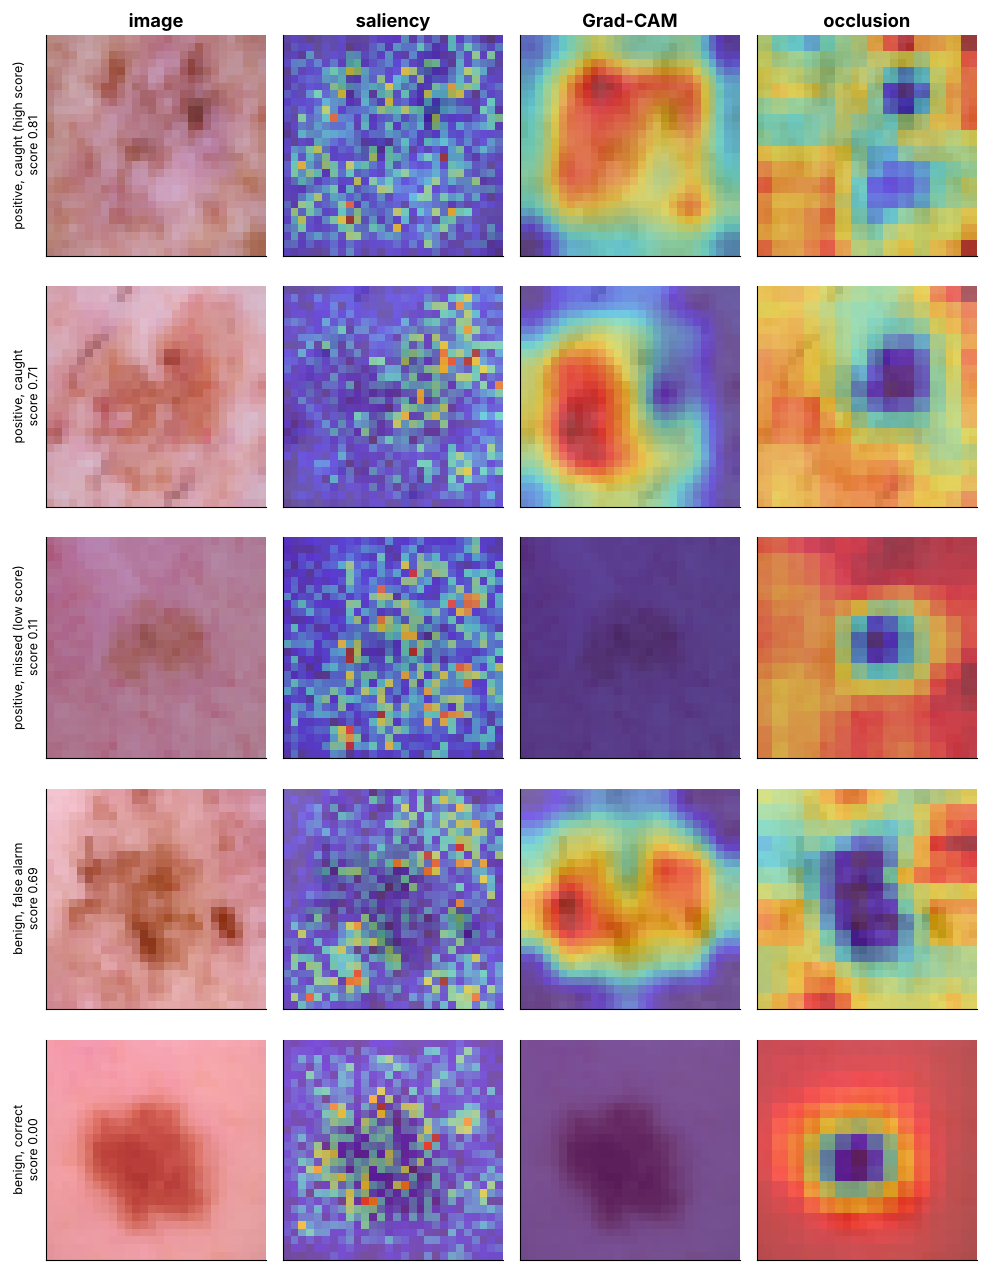

In [5]:
def saliency(m, x):
    x = x.clone().requires_grad_(True); m.zero_grad(); m(x).sum().backward()
    return x.grad.abs().amax(1).detach().numpy()                       # (n, 28, 28)

def gradcam(m, x):
    acts = {}
    h = m.features.register_forward_hook(lambda mod, i, o: acts.__setitem__("a", o))
    out = m(x); h.remove(); a = acts["a"]
    g = torch.autograd.grad(out.sum(), a)[0]
    cam = torch.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))   # standard Grad-CAM: keep only evidence FOR the positive class
    cam = torch.nn.functional.interpolate(cam, size=(28, 28), mode="bilinear", align_corners=False)
    return cam[:, 0].detach().numpy()

def occlusion(m, x, size=6, stride=2):
    base = predict_cnn(m, x); heat = np.zeros((len(x), 28, 28)); cnt = np.zeros((28, 28))
    for i in range(0, 28 - size + 1, stride):
        for j in range(0, 28 - size + 1, stride):
            xx = x.clone(); xx[:, :, i:i + size, j:j + size] = 0      # 0 = average colour after normalisation
            heat[:, i:i + size, j:j + size] += (base - predict_cnn(m, xx))[:, None, None]; cnt[i:i + size, j:j + size] += 1
    return heat / cnt

def norm01(h):
    h = h - h.min(axis=(1, 2), keepdims=True); return h / (h.max(axis=(1, 2), keepdims=True) + 1e-9)

def rank_corr(a, b):
    # Spearman correlation between two maps; undefined (NaN) when a map is flat, e.g. a Grad-CAM with no positive evidence
    if np.ptp(a) == 0 or np.ptp(b) == 0: return np.nan
    return spearmanr(a.ravel(), b.ravel())[0]
from scipy.stats import spearmanr

# Pick five instructive test images, using a 0.5 cut-off on the model's score
yt, pt = y["test"], p["test"]
pick = {"positive, caught (high score)": np.where(yt == 1)[0][np.argsort(-pt[yt == 1])[0]],
        "positive, caught": np.where(yt == 1)[0][np.argsort(-pt[yt == 1])[10]],
        "positive, missed (low score)": np.where(yt == 1)[0][np.argsort(pt[yt == 1])[3]],
        "benign, false alarm": np.where(yt == 0)[0][np.argsort(-pt[yt == 0])[2]],
        "benign, correct": np.where(yt == 0)[0][np.argsort(pt[yt == 0])[50]]}
ids = list(pick.values()); xs = T["test"][ids]
maps = {"saliency": norm01(saliency(model, xs)), "Grad-CAM": norm01(gradcam(model, xs)), "occlusion": norm01(occlusion(model, xs))}
fig, axes = plt.subplots(len(ids), 4, figsize=(10, 13))
for r, (label, i) in enumerate(pick.items()):
    axes[r, 0].imshow(data["test"]["X"][i]); axes[r, 0].set_ylabel(f"{label}\nscore {pt[i]:.2f}", fontsize=9)
    for c, (name, mp) in enumerate(maps.items(), start=1):
        axes[r, c].imshow(data["test"]["X"][i]); axes[r, c].imshow(mp[r], cmap="jet", alpha=0.5)
        if r == 0: axes[r, c].set_title(name)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_title("image"); plt.tight_layout(); plt.show()

**What this shows**

- Grad-CAM gives smooth blobs, usually over the lesion. Saliency looks like scattered noise. Occlusion often highlights the surrounding skin and image edges rather than the lesion centre
- The false alarm (row 4) gets a Grad-CAM map over the lesion that looks just as convincing as the correct cases
- For the missed positive and the correct benign case, Grad-CAM is blank: the network found nothing pushing towards positive. Blank means "no evidence for positive was found", not "this lesion is safe"
- **So what?** A heatmap over the lesion does not tell you the prediction is right. Also, each map uses its own colour scale, so brightness cannot be compared between images or methods

## 2. Do the three methods agree?

If all three maps revealed "the truth" about the model, they should roughly agree on which pixels matter. We check this on 100 positive test images. Some disagreement is expected, because the methods ask different questions; large disagreement means we cannot simply pick one and trust it

We use **Spearman rank correlation**: rank all pixels from most to least important in each map, then compare the two rankings. 1 means the same order, 0 means unrelated, and -1 means opposite order

### Measure agreement between the maps

For each pair of methods we compute the rank correlation on each image and average it. A completely blank Grad-CAM map cannot be ranked, so we count those and leave them out

In [6]:
from scipy.stats import spearmanr
sub = np.where(yt == 1)[0][:100]; xsub = T["test"][sub]
M = {"saliency": saliency(model, xsub), "Grad-CAM": gradcam(model, xsub), "occlusion": occlusion(model, xsub)}
names = list(M); agree = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        agree.loc[a, b] = np.nanmean([rank_corr(M[a][k], M[b][k]) for k in range(len(sub))])
display(agree.round(2))
print(f"Grad-CAM maps with no positive evidence at all (flat, left out of the averages): {sum(np.ptp(m) == 0 for m in M['Grad-CAM'])} of {len(sub)}")

,saliency,Grad-CAM,occlusion
saliency,1.00,0.02,-0.19
Grad-CAM,0.02,1.00,0.19
occlusion,-0.19,0.19,1.00


Grad-CAM maps with no positive evidence at all (flat, left out of the averages): 9 of 100


**What this shows** (table above)

- Correlations range from -0.19 to 0.19: the methods barely agree on which pixels matter. Saliency and occlusion even lean towards opposite rankings
- 9 of the 100 Grad-CAM maps were blank, even though all 100 images are positive
- **So what?** Three methods tell three different stories about the same predictions. We cannot judge a map by how it looks; we need tests that compare maps with the model's actual behaviour. That comes next

## 3. Sanity check: does the map depend on what the model learned?

A simple but revealing test ([Adebayo et al., 2018](https://arxiv.org/abs/1810.03292)): replace the trained weights with random numbers, so the model has learned nothing, and draw the maps again

- If the maps **barely change**, they were never really about the model. They mostly show the image itself, as an edge detector would
- If the maps **change a lot**, they at least depend on what the model learned. That is necessary, but not enough: it does not prove the map is accurate

We also compare each map with a plain edge detector that involves no model at all

### Replace learned weights with random values

We build a copy of the network with random weights, check its scores and redraw the maps for one image. Then we measure how similar the trained and random maps are

Randomised model, test AUROC 0.678, AUPRC 0.242 (no-skill references: AUROC 0.5, AUPRC 0.121)


,similarity trained vs random model,similarity to a plain edge detector
saliency,0.14,0.10
Grad-CAM,0.19,0.16
occlusion,0.08,-0.07


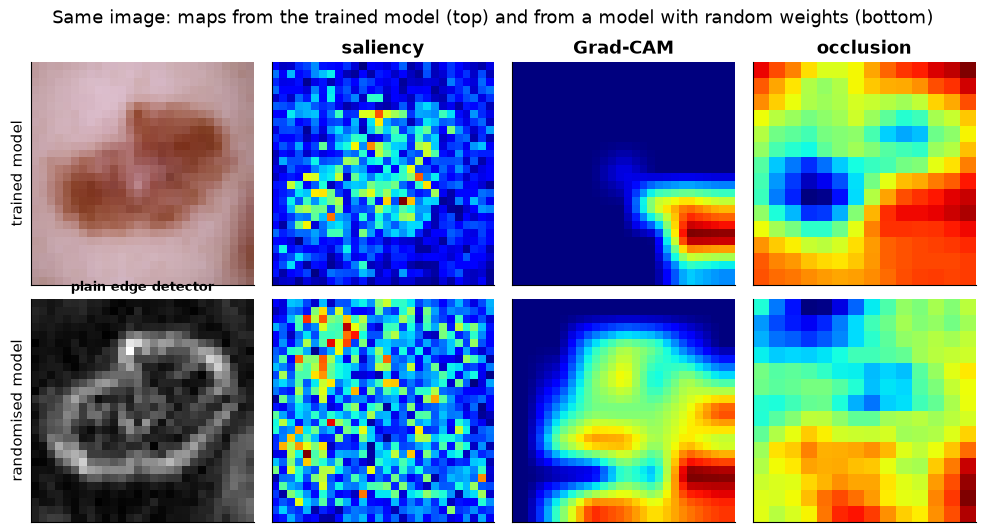

In [7]:
rand_model = SmallCNN(); torch.manual_seed(123)
for mod in rand_model.modules():
    if hasattr(mod, "reset_parameters"): mod.reset_parameters()
rand_model.eval()
p_rand = predict_cnn(rand_model, T["test"])
print(f"Randomised model, test AUROC {roc_auc_score(yt, p_rand):.3f}, AUPRC {average_precision_score(yt, p_rand):.3f} "
      f"(no-skill references: AUROC 0.5, AUPRC {yt.mean():.3f})")

Mr = {"saliency": saliency(rand_model, xsub), "Grad-CAM": gradcam(rand_model, xsub), "occlusion": occlusion(rand_model, xsub)}
gray_edges = np.abs(np.gradient(data["test"]["X"][sub].mean(3), axis=(1, 2))).sum(0)      # a plain edge detector, no model at all
sim = pd.DataFrame({"similarity trained vs random model": [np.nanmean([rank_corr(M[k][i], Mr[k][i]) for i in range(len(sub))]) for k in names],
                    "similarity to a plain edge detector": [np.nanmean([rank_corr(M[k][i], gray_edges[i]) for i in range(len(sub))]) for k in names]},
                   index=names)
display(sim.round(2))

fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))
i0 = 0
axes[0, 0].imshow(data["test"]["X"][sub[i0]]); axes[0, 0].set_ylabel("trained model"); axes[1, 0].imshow(gray_edges[i0], cmap="gray"); axes[1, 0].set_ylabel("randomised model")
axes[1, 0].set_title("plain edge detector", fontsize=9)
for c, k in enumerate(names, start=1):
    axes[0, c].imshow(M[k][i0], cmap="jet"); axes[0, c].set_title(k)
    axes[1, c].imshow(Mr[k][i0], cmap="jet")
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Same image: maps from the trained model (top) and from a model with random weights (bottom)"); plt.tight_layout(); plt.show()

**What this shows** (tables and maps above)

- Top row: maps from the trained model. Bottom row: maps from the random model, with a plain edge detector on the left
- Similarity between trained and random maps is low for all three methods (0.08 to 0.19), so all three pass this check: they depend on the learned weights
- The random model still reaches 0.678 AUROC, above chance. Even random filters respond to strong image features, such as a large dark area, which is also why an untrained model can produce maps with visible structure
- **So what?** Passing this check rules out the worst case, a map that ignores the model. It does not tell us whether the map points to what actually drives the prediction

## 4. Test the map: cover what it highlights

If a map really points to the pixels behind a positive prediction, covering those pixels should make the score drop fast, faster than covering random pixels

This is the **deletion test**: cover the most important 5%, 10% and so on up to 50% of pixels according to the map, and track the score. It is like deleting the sentences a summary calls "key" and checking whether the argument collapses

One caveat: "covering" means replacing pixels with the average colour, which creates unnatural images. So the test checks the map under one particular kind of change, not in every sense

### Cover important pixels and measure the effect

For the same 100 positive images, we cover pixels in the order each map ranks them, and compare with covering pixels at random. A lower average score while covering means the map found pixels that matter

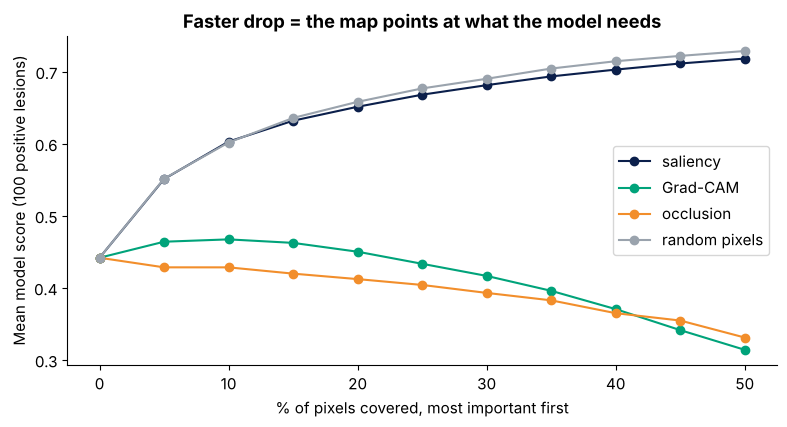

,average score while deleting (lower = more faithful)
saliency,0.641
Grad-CAM,0.414
occlusion,0.396
random pixels,0.648


In [8]:
fracs = np.linspace(0, 0.5, 11)
def deletion_curve(order_maps):
    out = []
    for f in fracs:
        k = int(f * 784); xx = xsub.clone()
        for n_ in range(len(sub)):
            if k == 0: break
            top = np.argsort(-order_maps[n_].ravel())[:k]; r, c = np.unravel_index(top, (28, 28))
            xx[n_, :, r, c] = 0
        out.append(predict_cnn(model, xx).mean())
    return np.array(out)
rng = np.random.default_rng(0)
curves = {k: deletion_curve(M[k]) for k in names}
curves["random pixels"] = deletion_curve(rng.random((len(sub), 28, 28)))
fig, ax = plt.subplots(figsize=(8, 4.4))
for k, c in curves.items():
    ax.plot(100 * fracs, c, "o-", label=k, color={"saliency": NAVY, "Grad-CAM": GREEN, "occlusion": ORANGE, "random pixels": GREY}[k])
ax.set_xlabel("% of pixels covered, most important first"); ax.set_ylabel("Mean model score (100 positive lesions)")
ax.set_title("Faster drop = the map points at what the model needs"); ax.legend(); plt.tight_layout(); plt.show()
display(pd.Series({k: c.mean() for k, c in curves.items()}, name="average score while deleting (lower = more faithful)").round(3).to_frame())

**What this shows** (table above)

- Covering pixels ranked by Grad-CAM or occlusion makes scores fall much faster than random covering: average score 0.41 and 0.40, versus 0.65 for random
- Saliency does almost exactly as well as random (0.64 versus 0.65), even though it passed the randomisation check
- **So what?** Each check catches a different problem. Saliency depends on the model, but here it does not point to what drives the prediction. Never trust a method after one test, and remember that Grad-CAM and occlusion passed only *this* test, with *this* kind of covering

## 5. Add a misleading clue to the training images

A **shortcut** is a clue that predicts the label in the training data but has nothing to do with the disease. Models happily learn shortcuts, because they are often easier to spot than the disease itself

This happens in practice. Dermatologists often draw around suspicious lesions with a surgical marker before photographing them. A melanoma classifier gave higher scores to lesions when such ink marks were present ([Winkler et al., 2019](https://doi.org/10.1001/jamadermatol.2019.1735))

We recreate this on purpose, so that we know the truth

- Paint a small purple square in the corner of 80% of positive training and validation images, but only 5% of benign ones
- Train the same network design on these images
- Test it three ways: on the original test images, with the mark added to every benign image, and with the mark added to every image

The mark never changes the diagnosis. So if adding it changes the score, the model is using the mark

### Train a model with a misleading mark

We train a "shortcut model" on the marked images, then compare it with the original "clean model" under each test condition. Before running: which condition will expose the shortcut?

trained 15 epochs in 56 s, selected validation AUROC 0.984, AUPRC 0.852


AUROC                      AUPRC  \
model                                  clean model shortcut model clean model   
test condition                                                                  
validation (with the same marks)             0.964          0.984       0.731   
clean test images                            0.944          0.941       0.665   
test, mark added to every benign image       0.935          0.628       0.634   
test, mark added to every image              0.944          0.928       0.662   

                                                       \
model                                  shortcut model   
test condition                                          
validation (with the same marks)                0.852   
clean test images                               0.650   
test, mark added to every benign image          0.145   
test, mark added to every image                 0.613   

                                       benign flagged at 0.5 (%)  \
model                                                clean model   
test condition                                                     
validation (with the same marks)                           3.137   
clean test images                                          2.412   
test, mark added to every benign image                     3.247   
test, mark added to every image                            3.247   

                                                       
model                                  shortcut model  
test condition                                         
validation (with the same marks)                1.373  
clean test images                               0.000  
test, mark added to every benign image         26.438  
test, mark added to every image                26.438

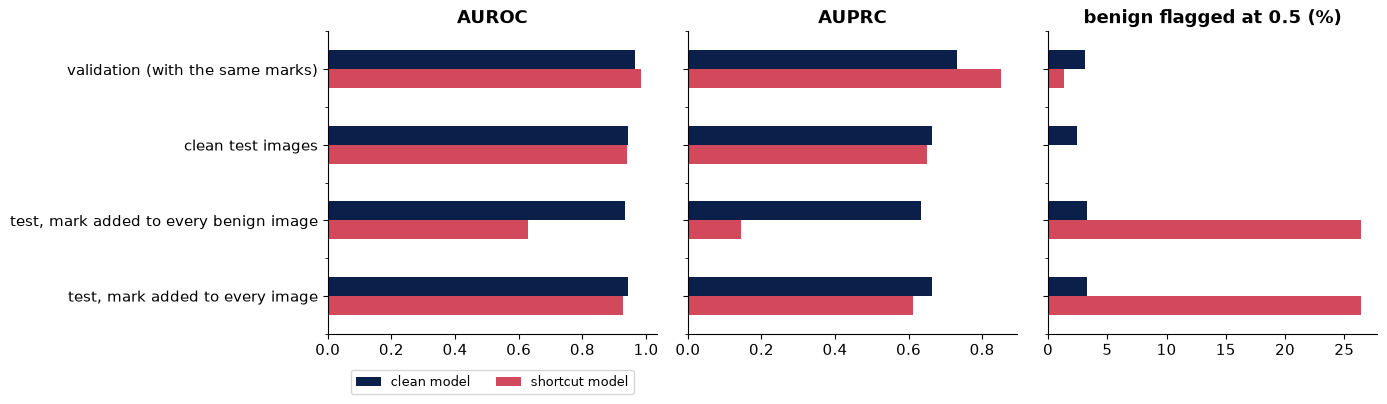

In [9]:
INK = np.array([120, 60, 170], dtype=np.uint8)
def add_mark(X, mask):
    X = X.copy(); X[mask, 1:6, 1:6] = INK; return X
rng = np.random.default_rng(1)
def biased_mask(yv): return np.where(yv == 1, rng.random(len(yv)) < 0.80, rng.random(len(yv)) < 0.05)
Xtr_s = add_mark(data["train"]["X"], biased_mask(y["train"])); Xva_s = add_mark(data["val"]["X"], biased_mask(y["val"]))
short_model, (mu_s, sd_s), _ = train_cnn(Xtr_s, y["train"], Xva_s, y["val"], seed=0)

Xte = data["test"]["X"]
tests = {"validation (with the same marks)": (Xva_s, y["val"]),
         "clean test images": (Xte, yt),
         "test, mark added to every benign image": (add_mark(Xte, yt == 0), yt),
         "test, mark added to every image": (add_mark(Xte, np.ones(len(yt), bool)), yt)}
rows = []
for name, (Xs, ys) in tests.items():
    for mname, m, (mu_, sd_) in [("clean model", model, (mu, sd)), ("shortcut model", short_model, (mu_s, sd_s))]:
        pp = predict_cnn(m, to_tensor(Xs, mu_, sd_))
        rows.append({"test condition": name, "model": mname, "AUROC": roc_auc_score(ys, pp), "AUPRC": average_precision_score(ys, pp),
                     "benign flagged at 0.5 (%)": 100 * (pp[ys == 0] >= 0.5).mean()})
res = pd.DataFrame(rows); display(res.pivot(index="test condition", columns="model").round(3).loc[list(tests)])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, col in zip(axes, ["AUROC", "AUPRC", "benign flagged at 0.5 (%)"]):
    pv = res.pivot(index="test condition", columns="model", values=col).loc[list(tests)]
    pv.plot.barh(ax=ax, color=[NAVY, RED]); ax.set_title(col); ax.set_ylabel("")
axes[0].invert_yaxis()
for ax in axes[1:]:
    ax.tick_params(axis="y", labelleft=False)
    ax.legend().remove()
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

**What this shows** (table above)

- On validation data with the same marks, the shortcut model looks *better* than the clean model: AUROC 0.984 versus 0.964. Validation rewarded the cheating, because it contained the same shortcut
- On clean test images, the two models perform about the same (AUROC 0.941 versus 0.944). Nothing looks wrong
- Add the mark to benign test images and the shortcut model collapses: AUROC drops to 0.628, and 26% of benign images are flagged, against 3% for the clean model, about eight times as many false alarms
- **So what?** A shortcut stays invisible as long as the test data share it. You find it only by deliberately changing the suspected clue. In a real clinic, the "mark" could be a ruler, a camera model or the hospital that took the photo

### Would the explanation map have warned us?

We add the mark to five benign test images, then compare scores and Grad-CAM maps from both models

,"shortcut model, no mark","shortcut model, with mark","clean model, with mark"
0,0.21,0.83,0.61
1,0.04,0.75,0.15
2,0.02,0.66,0.13
3,0.02,0.66,0.06
4,0.01,0.47,0.12


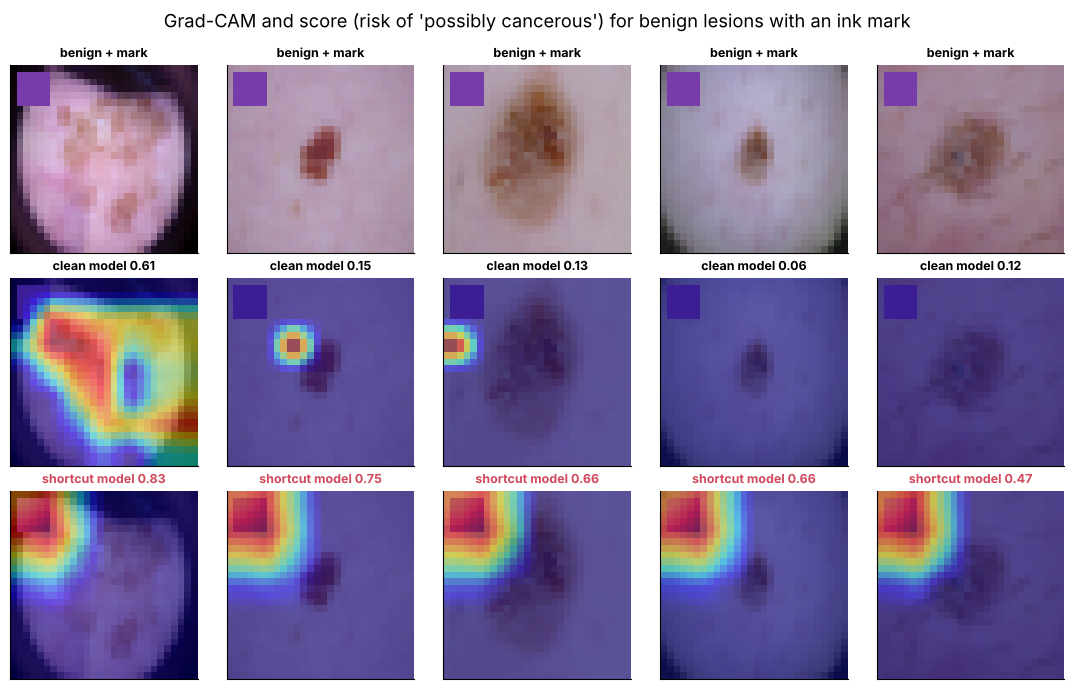

In [10]:
# Would an explanation map reveal the shortcut? Grad-CAM on benign test images with the mark added
ben = np.where(yt == 0)[0][:5]
Xm = add_mark(Xte[ben], np.ones(len(ben), bool))
Tm_short, Tm_clean = to_tensor(Xm, mu_s, sd_s), to_tensor(Xm, mu, sd)
cam_s, cam_c = norm01(gradcam(short_model, Tm_short)), norm01(gradcam(model, Tm_clean))
ps, pc = predict_cnn(short_model, Tm_short), predict_cnn(model, Tm_clean)
ps_unmarked = predict_cnn(short_model, to_tensor(Xte[ben], mu_s, sd_s))           # same images, no mark
display(pd.DataFrame({"shortcut model, no mark": ps_unmarked, "shortcut model, with mark": ps, "clean model, with mark": pc}).round(2))
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for k in range(5):
    axes[0, k].imshow(Xm[k]); axes[0, k].set_title("benign + mark", fontsize=9)
    axes[1, k].imshow(Xm[k]); axes[1, k].imshow(cam_c[k], cmap="jet", alpha=0.5); axes[1, k].set_title(f"clean model {pc[k]:.2f}", fontsize=9)
    axes[2, k].imshow(Xm[k]); axes[2, k].imshow(cam_s[k], cmap="jet", alpha=0.5); axes[2, k].set_title(f"shortcut model {ps[k]:.2f}", fontsize=9, color=RED)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Grad-CAM and score (risk of 'possibly cancerous') for benign lesions with an ink mark"); plt.tight_layout(); plt.show()

**What this shows**

- Adding the mark makes the shortcut model's score jump, for example from 0.04 to 0.75, pushing four of five benign lesions above 0.5
- The shortcut model's Grad-CAM maps light up the purple corner, not the lesion. Here, the map does reveal the shortcut
- The clean model flags one marked image too (score 0.61). Its maps sometimes highlight the mark as well (images 2 and 3), yet its scores stay low there: a highlighted region is not always one that drives the decision
- **So what?** The clearest evidence came from changing the input and watching the score; the map then helped show where to look. Real shortcuts are rarely as neat as a purple square, so maps alone will often miss them

## 6. Takeaways

**Key insights**

- Explanation maps help investigate a model; a convincing-looking map does not prove it is accurate
- Know which question each method answers, and test it: does it depend on the trained weights, and does covering what it highlights really change the score?
- The strongest evidence today came from changing the input on purpose and watching the score
- Validation cannot catch a shortcut that also appears in the validation data

**Common pitfalls**

- Treating a heatmap over the lesion as proof of a correct prediction
- Choosing a method because its maps look convincing
- Assuming one successful check proves the explanation is reliable
- Treating performance on the original data as proof of performance in a new clinic

**What this means for healthcare decision makers**

- Ask which explanation method was used and how it was tested
- Ask which collection patterns (marks, rulers, cameras, sites) could predict the label without reflecting the disease
- Request targeted tests that add, remove or change suspected clues

**Next session:** can we trust the model's risk numbers, where should the referral threshold be, and what happens with bad photos or under-represented groups?

**Check your understanding**

1. Why can an untrained model still produce a map with visible image structure?
2. Why did validation fail to warn us about the added mark?
3. What collection pattern might become a shortcut in intensive care data?